In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score
)

# Load real dataset
dataset = fetch_ucirepo(id=468)

X = dataset.data.features.copy()
y = dataset.data.targets["Revenue"].astype(int)

# Same data splitting as previous experiments
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)

categorical_cols = [
    "Month", "OperatingSystems", "Browser",
    "Region", "TrafficType", "VisitorType", "Weekend"
]

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (7398, 17)
Validation: (2466, 17)
Test: (2466, 17)


In [2]:

def build_tree(depth=4, class_weight=None):

    preprocessor = ColumnTransformer([
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),

        ("tree", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            min_samples_leaf=30,
            class_weight=class_weight,
            random_state=42
        ))
    ])

    return model


# First Decision Tree
tree_model = build_tree(depth=3)

tree_model.fit(X_train, y_train)

train_predictions = tree_model.predict(X_train)
val_predictions = tree_model.predict(X_val)

print("Train F1:",
      f1_score(y_train, train_predictions))

print("Validation F1:",
      f1_score(y_val, val_predictions))


Train F1: 0.6618769645262685
Validation F1: 0.6254927726675427


In [3]:

depths = [2, 4, 6, 10]
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

results = []
threshold_rows = []
tree_models = {}

for depth in depths:

    for weight in [None, "balanced"]:

        name = f"Depth={depth}, Weight={weight}"

        model = build_tree(
            depth=depth,
            class_weight=weight
        )

        model.fit(X_train, y_train)

        probs = model.predict_proba(X_val)[:, 1]

        # Fixed threshold
        fixed_pred = (probs >= 0.5).astype(int)

        fixed_f1 = f1_score(y_val, fixed_pred)

        # Independent threshold analysis
        for threshold in thresholds:

            predictions = (probs >= threshold).astype(int)

            threshold_rows.append({
                "Model": name,
                "Depth": depth,
                "Class Weight": str(weight),
                "Threshold": threshold,
                "Precision": precision_score(
                    y_val, predictions, zero_division=0
                ),
                "Recall": recall_score(
                    y_val, predictions, zero_division=0
                ),
                "F1": f1_score(
                    y_val, predictions, zero_division=0
                )
            })

        tree_models[name] = model

        results.append({
            "Model": name,
            "Depth": depth,
            "Class Weight": str(weight),
            "Train F1": f1_score(
                y_train, model.predict(X_train)
            ),
            "Validation F1 (0.5)": fixed_f1,
            "AP": average_precision_score(y_val, probs),
            "ROC-AUC": roc_auc_score(y_val, probs)
        })


results_df = pd.DataFrame(results)
threshold_df = pd.DataFrame(threshold_rows)

# Best threshold per model
best_indices = threshold_df.groupby("Model")["F1"].idxmax()

best_thresholds = threshold_df.loc[best_indices][
    ["Model", "Threshold", "Precision", "Recall", "F1"]
]

final_df = results_df.merge(
    best_thresholds,
    on="Model"
)

final_df = final_df.sort_values(
    "F1", ascending=False
)

print("Decision Tree Comparison on Validation:")
display(final_df.round(3))


Decision Tree Comparison on Validation:


,Model,Depth,Class Weight,Train F1,Validation F1 (0.5),AP,ROC-AUC,Threshold,Precision,Recall,F1
5,"Depth=6, Weight=balanced",6,balanced,0.645,0.625,0.702,0.929,0.72,0.612,0.806,0.695
3,"Depth=4, Weight=balanced",4,balanced,0.649,0.627,0.667,0.920,0.74,0.621,0.782,0.692
2,"Depth=4, Weight=None",4,None,0.661,0.658,0.685,0.919,0.27,0.635,0.740,0.684
0,"Depth=2, Weight=None",2,None,0.613,0.589,0.575,0.896,0.12,0.571,0.835,0.678
1,"Depth=2, Weight=balanced",2,balanced,0.664,0.676,0.563,0.896,0.42,0.563,0.845,0.676
4,"Depth=6, Weight=None",6,None,0.693,0.631,0.693,0.916,0.28,0.648,0.696,0.671
6,"Depth=10, Weight=None",10,None,0.689,0.624,0.673,0.909,0.36,0.640,0.696,0.667
7,"Depth=10, Weight=balanced",10,balanced,0.655,0.613,0.709,0.919,0.59,0.560,0.806,0.661


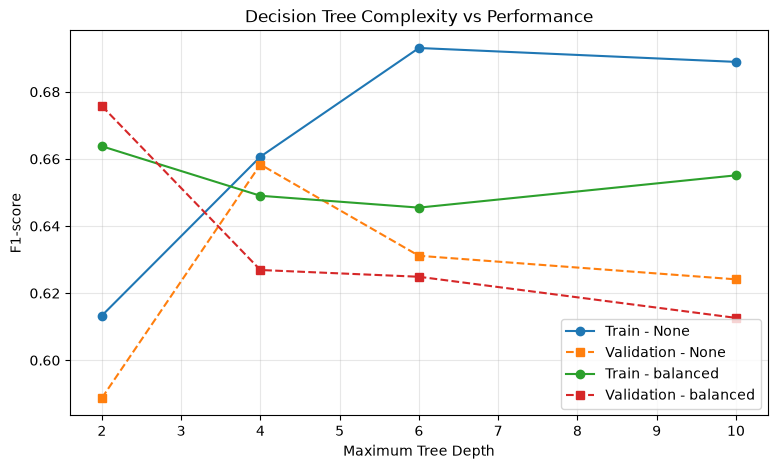

In [4]:

plt.figure(figsize=(9, 5))

for weight in ["None", "balanced"]:

    data = final_df[
        final_df["Class Weight"] == weight
    ].sort_values("Depth")

    plt.plot(
        data["Depth"],
        data["Train F1"],
        marker="o",
        label=f"Train - {weight}"
    )

    plt.plot(
        data["Depth"],
        data["Validation F1 (0.5)"],
        marker="s",
        linestyle="--",
        label=f"Validation - {weight}"
    )

plt.xlabel("Maximum Tree Depth")
plt.ylabel("F1-score")
plt.title("Decision Tree Complexity vs Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


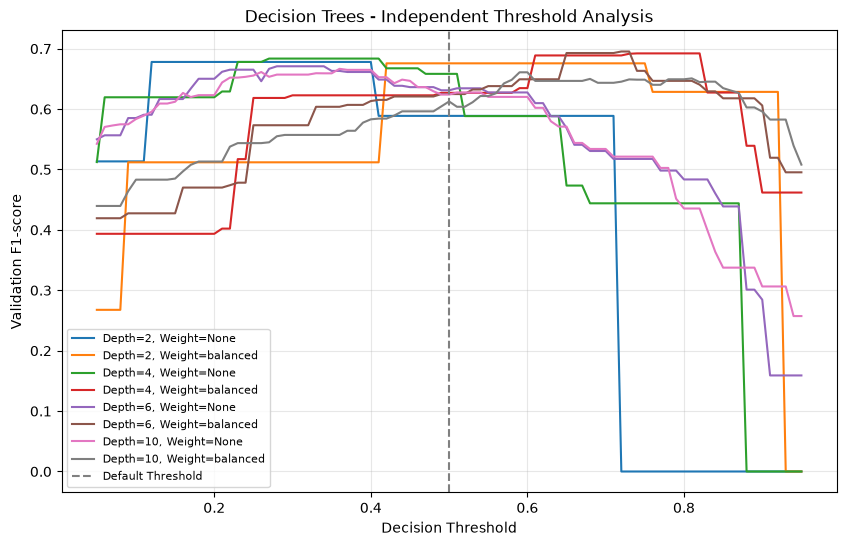

In [5]:

plt.figure(figsize=(10, 6))

for name in tree_models:

    data = threshold_df[
        threshold_df["Model"] == name
    ]

    plt.plot(
        data["Threshold"],
        data["F1"],
        label=name
    )

plt.axvline(
    x=0.5,
    linestyle="--",
    color="gray",
    label="Default Threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Validation F1-score")
plt.title("Decision Trees - Independent Threshold Analysis")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()


In [6]:
importance = pd.Series(
    trained_tree.feature_importances_,
    index=feature_names
)

print(
    importance.sort_values(
        ascending=False
    ).head(10)
)

NameError: name 'trained_tree' is not defined